Urządzenie obliczeniowe: cuda

--- WERYFIKACJA GENERATORA NA JEDNYM PRZYKŁADZIE ---
Indeksowanie od 0:
  Pozycje znaczników: [12 17]
  Pozycje wskazywanych wartości (t-8): [4 9]
  Pobrane wartości: [0.4237 0.3834] -> Suma obliczona: 0.8071 (Cel z tensora: 0.8071)
Indeksowanie od 1 (zgodnie z treścią zadania):
  Kroki znaczników: [13 18]
  Kroki wartości: [ 5 10]

Pole recepcyjne Conv1D [1, 2, 4]: 15 pozycji
Pole recepcyjne Conv1D [1, 1, 1]: 7 pozycji

==================== EKSPERYMENT DLA L = 50 ====================
Punkt odniesienia (stała predykcja = 1.0039) test MSE: 0.1598
[SimpleRNN (h=32)          ] L= 50 | MSE: 0.1598 | Czas:   3.0s | Parametry: 1185
[LSTM (h=32)               ] L= 50 | MSE: 0.1597 | Czas:   2.4s | Parametry: 4641
[GRU (h=32)                ] L= 50 | MSE: 0.1439 | Czas:   3.4s | Parametry: 3489
[Conv1D [1,2,4] (ch=64)    ] L= 50 | MSE: 0.1557 | Czas:   2.9s | Parametry: 25217

==================== EKSPERYMENT DLA L = 100 ====================
Punkt odniesienia (st

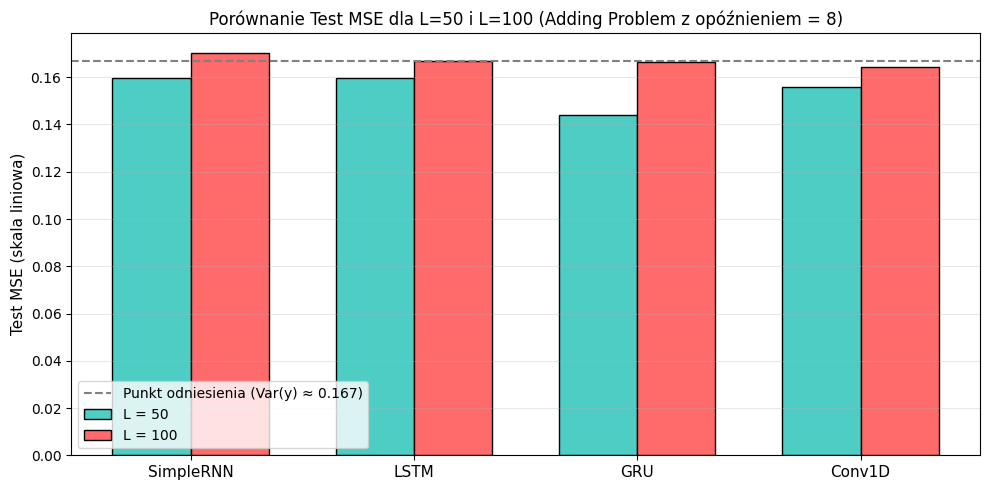


--- ANALIZA PRZYPADKU TESTOWEGO Z DUŻYM BŁĘDEM (Worst-case Sample) ---
Wybrana próbka testowa o największym błędzie (indeks #102):
  Pozycje znaczników m(t)=1 (indeks 0..99): [ 9 65] (kroki 1..100: [10 66])
  Wskazywane wartości v(t-8) (indeks 0..99): [ 1 57] (kroki 1..100: [ 2 58])
  Pobrane wartości liczbowe: [0.975  0.9859]
  Rzeczywista suma (Cel): 1.9609
  Predykcja SimpleRNN:    0.9420
  Błąd bezwzględny |y - y_hat|: 1.0189
  Błąd kwadratowy (y - y_hat)^2: 1.0381


In [1]:
import time
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt


DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
torch.manual_seed(0)
np.random.seed(0)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(0)

print(f"Urządzenie obliczeniowe: {DEVICE}")


def gen_delayed(N, L, delay=8):
    """
    Każda sekwencja: [N, L, 2]
    Kanał 0: losowe wartości v_t ~ U[0, 1]
    Kanał 1: znaczniki m_t in {0, 1}
    Znaczniki losowane na pozycjach p in [delay, L-1].
    Cel y: suma wartości z pozycji (p - delay).
    """
    val = np.random.rand(N, L, 1).astype(np.float32)
    mark = np.zeros((N, L, 1), dtype=np.float32)
    y = np.zeros((N, 1), dtype=np.float32)

    for i in range(N):

        p = np.random.choice(np.arange(delay, L), 2, replace=False)
        mark[i, p, 0] = 1.0

        target_positions = p - delay
        y[i, 0] = val[i, target_positions, 0].sum()

    x = np.concatenate([val, mark], axis=2)
    return torch.tensor(x).to(DEVICE), torch.tensor(y).to(DEVICE)


print("\n--- WERYFIKACJA GENERATORA NA JEDNYM PRZYKŁADZIE ---")
xx_sample, yy_sample = gen_delayed(1, 20, delay=8)
xx_np = xx_sample[0].cpu().numpy()
target_y = yy_sample[0, 0].item()

mark_pos_0based = np.where(xx_np[:, 1] == 1.0)[0]
val_pos_0based = mark_pos_0based - 8
vals = xx_np[val_pos_0based, 0]

print(f"Indeksowanie od 0:")
print(f"  Pozycje znaczników: {mark_pos_0based}")
print(f"  Pozycje wskazywanych wartości (t-8): {val_pos_0based}")
print(f"  Pobrane wartości: {vals.round(4)} -> Suma obliczona: {vals.sum():.4f} (Cel z tensora: {target_y:.4f})")
print(f"Indeksowanie od 1 (zgodnie z treścią zadania):")
print(f"  Kroki znaczników: {mark_pos_0based + 1}")
print(f"  Kroki wartości: {val_pos_0based + 1}")


class RNNNet(nn.Module):
    def __init__(self, typ, hidden=64):
        super().__init__()
        rnn_cls = {'RNN': nn.RNN, 'LSTM': nn.LSTM, 'GRU': nn.GRU}[typ]
        self.rnn = rnn_cls(input_size=2, hidden_size=hidden, batch_first=True)
        self.fc = nn.Linear(hidden, 1)

    def forward(self, x):
        out, _ = self.rnn(x)
        return self.fc(out[:, -1, :])

class ConvNetCustom(nn.Module):
    def __init__(self, ch=64, dilations=[1, 2, 4]):
        super().__init__()
        layers = []
        in_c = 2
        for d in dilations:

            layers.append(nn.Conv1d(in_c, ch, kernel_size=3, padding=d, dilation=d))
            layers.append(nn.ReLU())
            in_c = ch
        self.net = nn.Sequential(*layers)
        self.fc = nn.Linear(ch, 1)

    def forward(self, x):
        # x: [N, L, 2] -> Conv1D wymaga [N, 2, L]
        h = self.net(x.transpose(1, 2)).mean(dim=2)
        return self.fc(h)

def count_params(model):
    return sum(p.numel() for p in model.parameters())


def receptive_field(kernel_size, dilations):
    return 1 + (kernel_size - 1) * sum(dilations)

rf_dilated = receptive_field(3, [1, 2, 4])
rf_standard = receptive_field(3, [1, 1, 1])
print(f"\nPole recepcyjne Conv1D [1, 2, 4]: {rf_dilated} pozycji")
print(f"Pole recepcyjne Conv1D [1, 1, 1]: {rf_standard} pozycji")


def trenuj_model(model, Xtr, Ytr, Xte, Yte, epoki=30, lr=5e-3, batch=128):
    model = model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.MSELoss()
    n = len(Xtr)

    if DEVICE == 'cuda':
        torch.cuda.synchronize()
    t0 = time.time()

    for ep in range(epoki):
        model.train()
        perm = torch.randperm(n)
        for i in range(0, n, batch):
            idx = perm[i:i + batch]
            opt.zero_grad()
            loss = criterion(model(Xtr[idx]), Ytr[idx])
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()

    if DEVICE == 'cuda':
        torch.cuda.synchronize()
    czas = time.time() - t0

    model.eval()
    with torch.no_grad():
        pred_te = model(Xte)
        mse = criterion(pred_te, Yte).item()

    return mse, czas, model, pred_te


wyniki = []
modele_zapisane = {}
prognozy_zapisane = {}
test_sets = {}

dlugosci = [50, 100]

for L in dlugosci:
    print(f"\n==================== EKSPERYMENT DLA L = {L} ====================")

    Xtr, Ytr = gen_delayed(N=4000, L=L, delay=8)
    Xte, Yte = gen_delayed(N=800, L=L, delay=8)
    test_sets[L] = (Xte, Yte)


    mean_tr = Ytr.mean().item()
    baseline_mse = ((Yte - mean_tr)**2).mean().item()
    print(f"Punkt odniesienia (stała predykcja = {mean_tr:.4f}) test MSE: {baseline_mse:.4f}")

    wyniki.append({
        'Model': f'Baseline (Średnia Ytr)',
        'L': L,
        'Parametry': 0,
        'MSE': baseline_mse,
        'Czas [s]': 0.0
    })


    modele_L = {
        'SimpleRNN (h=32)': RNNNet('RNN', hidden=32),
        'LSTM (h=32)': RNNNet('LSTM', hidden=32),
        'GRU (h=32)': RNNNet('GRU', hidden=32),
        'Conv1D [1,2,4] (ch=64)': ConvNetCustom(ch=64, dilations=[1, 2, 4])
    }


    if L == 100:
        modele_L['SimpleRNN (h=64) [MOD]'] = RNNNet('RNN', hidden=64)
        modele_L['Conv1D [1,1,1] (ch=64) [MOD]'] = ConvNetCustom(ch=64, dilations=[1, 1, 1])

    for nazwa, mod in modele_L.items():
        params = count_params(mod)
        mse, czas, trained_mod, pred_te = trenuj_model(mod, Xtr, Ytr, Xte, Yte, epoki=30, lr=5e-3, batch=128)
        wyniki.append({
            'Model': nazwa,
            'L': L,
            'Parametry': params,
            'MSE': mse,
            'Czas [s]': czas
        })
        modele_zapisane[(nazwa, L)] = trained_mod
        prognozy_zapisane[(nazwa, L)] = pred_te
        print(f"[{nazwa:26s}] L={L:3d} | MSE: {mse:.4f} | Czas: {czas:5.1f}s | Parametry: {params}")


print("\n" + "="*80)
print(f"{'Model':<30} | {'L':<4} | {'Parametry':<10} | {'Test MSE':<10} | {'Czas [s]':<8}")
print("-" * 80)
for r in wyniki:
    print(f"{r['Model']:<30} | {r['L']:<4} | {r['Parametry']:<10} | {r['MSE']:<10.4f} | {r['Czas [s]']:<8.1f}")
print("="*80)


plt.figure(figsize=(10, 5))
modele_glowne = ['SimpleRNN (h=32)', 'LSTM (h=32)', 'GRU (h=32)', 'Conv1D [1,2,4] (ch=64)']
bar_width = 0.35
indices = np.arange(len(modele_glowne))

mse_L50 = [next(r['MSE'] for r in wyniki if r['Model'] == m and r['L'] == 50) for m in modele_glowne]
mse_L100 = [next(r['MSE'] for r in wyniki if r['Model'] == m and r['L'] == 100) for m in modele_glowne]

plt.bar(indices - bar_width/2, mse_L50, width=bar_width, label='L = 50', color='#4ecdc4', edgecolor='black')
plt.bar(indices + bar_width/2, mse_L100, width=bar_width, label='L = 100', color='#ff6b6b', edgecolor='black')

plt.axhline(0.167, ls='--', color='gray', linewidth=1.5, label='Punkt odniesienia (Var(y) ≈ 0.167)')
plt.xticks(indices, ['SimpleRNN', 'LSTM', 'GRU', 'Conv1D'], fontsize=11)
plt.ylabel('Test MSE (skala liniowa)', fontsize=11)
plt.title('Porównanie Test MSE dla L=50 i L=100 (Adding Problem z opóźnieniem = 8)', fontsize=12)
plt.legend(fontsize=10)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('wykres_porownawczy_L50_L100.png', dpi=150)
plt.show()

print("\n--- ANALIZA PRZYPADKU TESTOWEGO Z DUŻYM BŁĘDEM (Worst-case Sample) ---")

model_name = 'SimpleRNN (h=32)'
Xte_100, Yte_100 = test_sets[100]
preds_rnn = prognozy_zapisane[(model_name, 100)].cpu().numpy().ravel()
y_true = Yte_100.cpu().numpy().ravel()

sq_errors = (y_true - preds_rnn)**2
worst_idx = np.argmax(sq_errors)

x_worst = Xte_100[worst_idx].cpu().numpy()
val_channel = x_worst[:, 0]
mark_channel = x_worst[:, 1]

mark_indices_0 = np.where(mark_channel == 1.0)[0]
val_indices_0 = mark_indices_0 - 8
selected_vals = val_channel[val_indices_0]

print(f"Wybrana próbka testowa o największym błędzie (indeks #{worst_idx}):")
print(f"  Pozycje znaczników m(t)=1 (indeks 0..99): {mark_indices_0} (kroki 1..100: {mark_indices_0 + 1})")
print(f"  Wskazywane wartości v(t-8) (indeks 0..99): {val_indices_0} (kroki 1..100: {val_indices_0 + 1})")
print(f"  Pobrane wartości liczbowe: {selected_vals.round(4)}")
print(f"  Rzeczywista suma (Cel): {y_true[worst_idx]:.4f}")
print(f"  Predykcja SimpleRNN:    {preds_rnn[worst_idx]:.4f}")
print(f"  Błąd bezwzględny |y - y_hat|: {abs(y_true[worst_idx] - preds_rnn[worst_idx]):.4f}")
print(f"  Błąd kwadratowy (y - y_hat)^2: {sq_errors[worst_idx]:.4f}")